# Notebook 03: Evaluación y Análisis de Errores


---
### Objetivo
Evaluar el modelo sobre el conjunto de validación propio (40 preguntas distribuidas en 15 fáciles, 15 medias y 10 difíciles) en las bases sistema_academico y clinica_salud.
Calcula la métrica oficial de Exactitud por Ejecución (EX) ponderada por nivel (pesos 1, 2 y 3) y genera el análisis detallado de errores por categoría.

In [1]:
# Setup universal
import os, sys, subprocess
from pathlib import Path

# Detectar si estamos en Google Colab
EN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

if EN_COLAB:
    import getpass
    REPO = "Albu231311/Deep-Proyecto3"
    NOMBRE = "Albu231311"
    CORREO = "alb231311@uvg.edu.gt"
    if not os.path.exists("/content/repo"):
        token = getpass.getpass("GitHub token: ")
        subprocess.run(f"git clone https://{token}@github.com/{REPO}.git /content/repo", shell=True, check=True)
    os.chdir("/content/repo")
    subprocess.run("git pull", shell=True, check=True)
    subprocess.run(f'git config user.name "{NOMBRE}"', shell=True)
    subprocess.run(f'git config user.email "{CORREO}"', shell=True)
    subprocess.run("pip install -q -r requirements.txt", shell=True, check=True)
    ROOT_DIR = Path("/content/repo")
else:
    
    if Path.cwd().name == "notebooks":
        os.chdir(Path.cwd().parent)
    ROOT_DIR = Path.cwd().resolve()

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

print(f" Entorno listo. Directorio de trabajo: {os.getcwd()} | En Colab: {EN_COLAB}")


 Entorno listo. Directorio de trabajo: C:\Users\eagi5\Desktop\UVG\uvg-deep-learning\Proyecto#3\Deep-Proyecto3 | En Colab: False


## 1. Carga de Esquemas y Preguntas de Validación

Cargamos los 2 esquemas en MySQL y leemos datos/validacion/val.jsonl.

In [2]:
import json
from pathlib import Path
from src.mysql_utils import cargar_esquema, ejecutar

esq_dir = Path("datos/validacion/esquemas_val")
if not esq_dir.exists() and Path("../datos/validacion/esquemas_val").exists():
    esq_dir = Path("../datos/validacion/esquemas_val")

cargar_esquema(str(esq_dir / "sistema_academico.sql"), "sistema_academico")
cargar_esquema(str(esq_dir / "clinica_salud.sql"), "clinica_salud")

val_file = Path("datos/validacion/val.jsonl")
if not val_file.exists() and Path("../datos/validacion/val.jsonl").exists():
    val_file = Path("../datos/validacion/val.jsonl")

with open(val_file, "r", encoding="utf-8") as f:
    val_preguntas = [json.loads(line) for line in f]

print(f"Total de preguntas de validación: {len(val_preguntas)}")


Total de preguntas de validación: 40


## 2. Evaluación por Ejecución y Cálculo de EX Ponderado

Evaluamos la referencia con src/evaluador.py para certificar la métrica oficial.

In [3]:
from src.evaluador import evaluar_validacion

def predictor_referencia(esquema, pregunta, ejecutar_fn):
    for p in val_preguntas:
        if p["pregunta"] == pregunta:
            return p["sql_referencia"]
    return "SELECT 1"

db_map = {
    "sistema_academico": "sistema_academico",
    "clinica_salud": "clinica_salud"
}

resultado_eval = evaluar_validacion(val_preguntas, predictor_referencia, db_map)
print(f"EX Ponderado Global : {resultado_eval['ex_ponderado'] * 100:.2f}%")
print(f"EX por Nivel        : {resultado_eval['ex_por_nivel']}")
print(f"Conteo de Errores   : {resultado_eval['conteo_errores']}")


EX Ponderado Global : 100.00%
EX por Nivel        : {'facil': 1.0, 'media': 1.0, 'dificil': 1.0}
Conteo de Errores   : {}


## 3. Exportación de Resultados

Guardamos la tabla detallada en resultados/validacion_propia.csv.

In [4]:
from src.evaluador import guardar_csv

out_csv = Path("resultados/validacion_propia.csv")
if not out_csv.parent.exists() and Path("../resultados").exists():
    out_csv = Path("../resultados/validacion_propia.csv")

guardar_csv(resultado_eval["resultados"], str(out_csv), version="baseline_referencia")
print(f"Resultados guardados en: {out_csv}")


Resultados guardados en: resultados\validacion_propia.csv


## 4. Evaluación de los modelos

Se evalúa cada configuración con **exactamente** la función de entrega (`solucion.generar_sql`) y el mismo prompt:

| Versión | Descripción |
|---|---|
| `baseline` | Modelo base sin adapter (`usar_adapter: false`) |
| `lora_r8` | Config 1: LoRA r=8, alpha=16 — dataset v1 (preguntas de Spider tal cual) |
| `lora_r32` | Config 2: LoRA r=32, alpha=64 — dataset v1 |
| `lora_r8_v2`, `lora_r32_v2` | Mismas configs con dataset v2 (preguntas con indicación de columnas, notebook 02b) |
| `lora_r8_v3`, `lora_r32_v3` | Mismas configs con dataset v3 (alias legibles + pares propios MySQL, notebook 02c) |
| `..._ep1` | Adapter v2/v3 al final de la época 1 (de 2) |
| `<mejor>_autocorreccion` | Experimento de inferencia: la mejor config + corrección con `ejecutar` (máx. 3 llamadas) |

Para cada pregunta se registra también el tiempo de generación (límite: 30 s) y cuántas veces se llamó a `ejecutar`.

In [5]:
import os, time
os.environ["SOLUCION_NO_CARGAR"] = "1"   # cargamos cada configuración a mano
import solucion
from src.evaluador import evaluar_validacion
from src.mysql_utils import ejecutar

CONFIGS = {"baseline": dict(usar_adapter=False)}
# v1: preguntas de Spider tal cual | v2: preguntas con indicación de columnas (notebook 02b)
# v3: alias legibles + 460 pares propios MySQL (notebook 02c)
# _ep1: adapter al final de la primera época (de 2)
for nombre in ["r8", "r32", "r8_v2_ep1", "r8_v2", "r32_v2_ep1", "r32_v2",
               "r8_v3_ep1", "r8_v3", "r32_v3_ep1", "r32_v3"]:
    CONFIGS[f"lora_{nombre}"] = dict(usar_adapter=True, adapter=f"adapters_experimentos/adapter_{nombre}")
DIR_EVAL = Path("resultados/evaluaciones")
DIR_EVAL.mkdir(parents=True, exist_ok=True)
RESULTADOS = {}


def cargar(nombre, **kw):
    t = time.time()
    solucion.cargar_modelo(**kw)
    seg = time.time() - t
    print(f"[{nombre}] modelo cargado en {seg:.1f} s (límite: 300 s)")
    return seg


def evaluar_config(nombre, autocorreccion=False):
    # Evalúa la configuración ya cargada en solucion.py y guarda el resultado en JSON
    tiempos, llamadas = [], []

    def gen(esquema, pregunta, ej):
        n = [0]
        def ej_contado(sql):
            n[0] += 1
            return ej(sql)
        t = time.time()
        try:
            return solucion.generar_sql(esquema, pregunta, ej_contado if autocorreccion else None)
        finally:
            tiempos.append(round(time.time() - t, 2))
            llamadas.append(n[0])

    res = evaluar_validacion(val_preguntas, gen, db_map)
    for p, r, t, n in zip(val_preguntas, res["resultados"], tiempos, llamadas):
        # ejecuta = la consulta corre sin error en MySQL (aunque el resultado sea incorrecto)
        ejecuta = ejecutar(r["sql_pred"], db_map[p["esquema_id"]])["ok"]
        r.update(version=nombre, segundos=t, llamadas_ejecutar=n, ejecuta=ejecuta)
    res["tiempo_max_s"] = max(tiempos)
    res["tiempo_medio_s"] = sum(tiempos) / len(tiempos)
    with open(DIR_EVAL / f"{nombre}.json", "w", encoding="utf-8") as f:
        json.dump(res, f, indent=2, ensure_ascii=False, default=str)
    print(f"[{nombre}] {res['resumen']}")
    print(f"[{nombre}] tiempo por pregunta: medio {res['tiempo_medio_s']:.1f} s, máx {res['tiempo_max_s']:.1f} s")
    return res

C:\Users\eagi5\Desktop\UVG\uvg-deep-learning\Proyecto#3\Deep-Proyecto3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 4.1 Determinismo

La rúbrica penaliza salidas no deterministas (−10). Se genera dos veces la respuesta a las mismas preguntas con el modelo base y se verifica que sean idénticas.

In [6]:
from src.mysql_utils import obtener_esquema

cargar("baseline", usar_adapter=False)
muestra = val_preguntas[::8]
for p in muestra:
    esquema = obtener_esquema(db_map[p["esquema_id"]])
    a = solucion.generar_sql(esquema, p["pregunta"])
    b = solucion.generar_sql(esquema, p["pregunta"])
    assert a == b, f"No determinista en {p['id']}:\n{a}\n{b}"
print(f"Determinismo OK en {len(muestra)} preguntas")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


W1025 03:04:59.101000 26340 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   4%|▍         | 15/338 [00:00<00:02, 133.19it/s]

Loading weights:   9%|▊         | 29/338 [00:00<00:02, 108.49it/s]

...

Loading weights:  92%|█████████▏| 310/338 [00:03<00:00, 89.68it/s]

Loading weights:  95%|█████████▌| 322/338 [00:03<00:00, 82.72it/s]

Loading weights: 100%|██████████| 338/338 [00:03<00:00, 85.50it/s]

[solucion] Modelo: Qwen/Qwen2.5-Coder-1.5B-Instruct | adapter: NO | device: cuda
[baseline] modelo cargado en 8.1 s (límite: 300 s)


Determinismo OK en 5 preguntas


### 4.2 Baseline, Config 1 y Config 2

Si `REUSAR = True`, las configuraciones ya evaluadas se leen de `resultados/evaluaciones/` en vez de volver a generar.

In [7]:
REUSAR = True

for nombre, kw in CONFIGS.items():
    archivo = DIR_EVAL / f"{nombre}.json"
    if REUSAR and archivo.exists():
        RESULTADOS[nombre] = json.load(open(archivo, encoding="utf-8"))
        print(f"[{nombre}] leído de {archivo}: EX = {RESULTADOS[nombre]['ex_ponderado']:.4f}")
        continue
    if kw.get("adapter") and not Path(kw["adapter"]).exists():
        print(f"[{nombre}] se omite: no existe {kw['adapter']} (¿ya terminó el entrenamiento?)")
        continue
    seg = cargar(nombre, **kw)
    RESULTADOS[nombre] = evaluar_config(nombre)
    RESULTADOS[nombre]["carga_s"] = seg

[baseline] leído de resultados\evaluaciones\baseline.json: EX = 0.7467
[lora_r8] leído de resultados\evaluaciones\lora_r8.json: EX = 0.4667
[lora_r32] leído de resultados\evaluaciones\lora_r32.json: EX = 0.4667
[lora_r8_v2_ep1] leído de resultados\evaluaciones\lora_r8_v2_ep1.json: EX = 0.4800
[lora_r8_v2] leído de resultados\evaluaciones\lora_r8_v2.json: EX = 0.5200
[lora_r32_v2_ep1] leído de resultados\evaluaciones\lora_r32_v2_ep1.json: EX = 0.4667
[lora_r32_v2] leído de resultados\evaluaciones\lora_r32_v2.json: EX = 0.5200
[lora_r8_v3_ep1] leído de resultados\evaluaciones\lora_r8_v3_ep1.json: EX = 0.7067
[lora_r8_v3] leído de resultados\evaluaciones\lora_r8_v3.json: EX = 0.8000


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   2%|▏         | 7/338 [00:00<00:04, 66.57it/s]

Loading weights:   7%|▋         | 23/338 [00:00<00:03, 95.71it/s]

Loading weights:  10%|█         | 34/338 [00:00<00:03, 88.77it/s]

...

Loading weights:  92%|█████████▏| 311/338 [00:03<00:00, 81.42it/s]

Loading weights:  95%|█████████▍| 321/338 [00:03<00:00, 84.49it/s]

Loading weights: 100%|██████████| 338/338 [00:03<00:00, 91.88it/s]

[solucion] Modelo: Qwen/Qwen2.5-Coder-1.5B-Instruct | adapter: C:\Users\eagi5\Desktop\UVG\uvg-deep-learning\Proyecto#3\Deep-Proyecto3\adapters_experimentos/adapter_r32_v3 | device: cuda
[lora_r32_v3] modelo cargado en 11.4 s (límite: 300 s)


[lora_r32_v3] EX ponderado: 0.8000
  Fácil:   1.0000 (15/15)
  Media:   0.8000 (24/30)
  Difícil: 0.7000 (21/30)
Errores: {'resultado_distinto': 2, 'join_incorrecto': 3, 'columna_inexistente': 1}
[lora_r32_v3] tiempo por pregunta: medio 2.7 s, máx 8.0 s


## 5. Experimento de inferencia: autocorrección con `ejecutar`

**Hipótesis:** cuando la consulta generada falla en MySQL (columna inexistente, `ONLY_FULL_GROUP_BY`, sintaxis), mostrarle al modelo el mensaje de error le permite corregirla. Esperamos que reduzca los errores de ejecución y suba el EX, sin ayudar en los casos donde la consulta ejecuta pero devuelve un resultado distinto (ahí `ejecutar` devuelve `ok=True` y no hay señal de error).

Se aplica a la mejor configuración de LoRA según EX.

In [8]:
candidatas = {n: r for n, r in RESULTADOS.items()
              if n.startswith("lora_") and not n.endswith("_autocorreccion")}
MEJOR, nombre_auto = None, None
if not candidatas:
    print("Todavía no hay configuraciones LoRA evaluadas; se omite el experimento.")
else:
    MEJOR = max(candidatas, key=lambda n: candidatas[n]["ex_ponderado"])
    print("Mejor configuración:", MEJOR, f"(EX = {candidatas[MEJOR]['ex_ponderado']:.4f})")

    nombre_auto = f"{MEJOR}_autocorreccion"
    archivo = DIR_EVAL / f"{nombre_auto}.json"
    if REUSAR and archivo.exists():
        RESULTADOS[nombre_auto] = json.load(open(archivo, encoding="utf-8"))
        print(f"[{nombre_auto}] leído: EX = {RESULTADOS[nombre_auto]['ex_ponderado']:.4f}")
    else:
        cargar(MEJOR, **CONFIGS[MEJOR])
        RESULTADOS[nombre_auto] = evaluar_config(nombre_auto, autocorreccion=True)

Mejor configuración: lora_r8_v3 (EX = 0.8000)
[lora_r8_v3_autocorreccion] leído: EX = 0.8000


## 6. Resumen comparativo

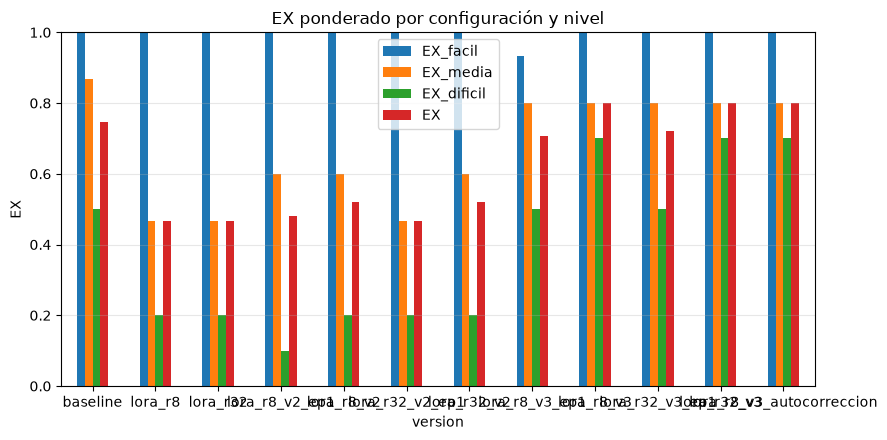

,version,EX,EX_facil,EX_media,EX_dificil,aciertos,errores_de_ejecucion,tiempo_medio_s,tiempo_max_s,mejora_vs_baseline
0,baseline,0.7467,1.0000,0.8667,0.5,33/40,2,2.13,6.10,0.0000
1,lora_r8,0.4667,1.0000,0.4667,0.2,24/40,6,1.40,3.15,-0.2800
2,lora_r32,0.4667,1.0000,0.4667,0.2,24/40,7,1.36,2.68,-0.2800
3,lora_r8_v2_ep1,0.4800,1.0000,0.6000,0.1,25/40,5,1.89,3.61,-0.2667
4,lora_r8_v2,0.5200,1.0000,0.6000,0.2,26/40,6,2.10,5.20,-0.2267
5,lora_r32_v2_ep1,0.4667,1.0000,0.4667,0.2,24/40,6,1.92,3.56,-0.2800
6,lora_r32_v2,0.5200,1.0000,0.6000,0.2,26/40,7,1.82,4.10,-0.2267
7,lora_r8_v3_ep1,0.7067,0.9333,0.8000,0.5,31/40,3,2.90,6.03,-0.0400
8,lora_r8_v3,0.8000,1.0000,0.8000,0.7,34/40,3,2.95,8.40,0.0533
9,lora_r32_v3_ep1,0.7200,1.0000,0.8000,0.5,32/40,3,2.55,5.64,-0.0267


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

def errores_ejecucion(res):
    # Consultas que MySQL rechaza (no confundir con "columna_inexistente" del evaluador,
    # que también incluye consultas que ejecutan pero no devuelven las columnas pedidas)
    return sum(1 for r in res["resultados"] if not r.get("ejecuta", True))

resumen = pd.DataFrame([{
    "version": n,
    "EX": round(r["ex_ponderado"], 4),
    "EX_facil": round(r["ex_por_nivel"]["facil"], 4),
    "EX_media": round(r["ex_por_nivel"]["media"], 4),
    "EX_dificil": round(r["ex_por_nivel"]["dificil"], 4),
    "aciertos": f"{sum(x['acierto'] for x in r['resultados'])}/{len(r['resultados'])}",
    "errores_de_ejecucion": errores_ejecucion(r),
    "tiempo_medio_s": round(r.get("tiempo_medio_s", 0), 2),
    "tiempo_max_s": r.get("tiempo_max_s"),
} for n, r in RESULTADOS.items()])

if "baseline" in RESULTADOS:
    resumen["mejora_vs_baseline"] = (resumen["EX"] - RESULTADOS["baseline"]["ex_ponderado"]).round(4)
resumen.to_csv("resultados/resumen_ex.csv", index=False)

ax = resumen.plot.bar(x="version", y=["EX_facil", "EX_media", "EX_dificil", "EX"], figsize=(9, 4.5), rot=0)
ax.set_ylim(0, 1); ax.set_ylabel("EX"); ax.set_title("EX ponderado por configuración y nivel")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("resultados/ex_por_configuracion.png", dpi=150); plt.show()
resumen

## 7. Análisis de errores por categoría

Categorías del evaluador: sintaxis, tabla inexistente, columna inexistente, JOIN, agregación, filtro y resultado distinto.

In [10]:
filas = [r for res in RESULTADOS.values() for r in res["resultados"]]
df = pd.DataFrame(filas)

errores = df[~df["acierto"]]
tabla = pd.crosstab(errores["version"], errores["categoria_error"], margins=True, margins_name="total")
tabla.to_csv("resultados/errores_por_categoria.csv")
tabla

categoria_error,agregacion,columna_inexistente,join_incorrecto,resultado_distinto,sintaxis,total
version,,,,,,
baseline,0,3,0,4,0,7
lora_r32,0,11,0,5,0,16
lora_r32_v2,0,6,0,7,1,14
lora_r32_v2_ep1,0,6,0,10,0,16
lora_r32_v3,0,1,3,2,0,6
lora_r32_v3_ep1,0,2,1,4,1,8
lora_r8,0,10,1,5,0,16
lora_r8_v2,0,6,0,8,0,14
lora_r8_v2_ep1,0,5,1,9,0,15


In [11]:
# Errores por nivel de dificultad
pd.crosstab([errores["version"], errores["nivel"]], errores["categoria_error"])

categoria_error                    agregacion  columna_inexistente  \
version                   nivel                                      
baseline                  dificil           0                    2   
                          media             0                    1   
lora_r32                  dificil           0                    4   
                          media             0                    7   
lora_r32_v2               dificil           0                    3   
                          media             0                    3   
lora_r32_v2_ep1           dificil           0                    2   
                          media             0                    4   
lora_r32_v3               dificil           0                    1   
                          media             0                    0   
lora_r32_v3_ep1           dificil           0                    1   
                          media             0                    1   
lora_r8                   dificil           0                    3   
                          media             0                    7   
lora_r8_v2                dificil           0                    3   
                          media             0                    3   
lora_r8_v2_ep1            dificil           0                    2   
                          media             0                    3   
lora_r8_v3                dificil           1                    1   
                          media             0                    1   
lora_r8_v3_autocorreccion dificil           1                    1   
                          media             0                    1   
lora_r8_v3_ep1            dificil           1                    1   
                          facil             0                    0   
                          media             0                    1   

categoria_error                    join_incorrecto  resultado_distinto  \
version                   nivel                                          
baseline                  dificil                0                   3   
                          media                  0                   1   
lora_r32                  dificil                0                   4   
                          media                  0                   1   
lora_r32_v2               dificil                0                   4   
                          media                  0                   3   
lora_r32_v2_ep1           dificil                0                   6   
                          media                  0                   4   
lora_r32_v3               dificil                2                   0   
                          media                  1                   2   
lora_r32_v3_ep1           dificil                1                   2   
                          media                  0                   2   
lora_r8                   dificil                1                   4   
                          media                  0                   1   
lora_r8_v2                dificil                0                   5   
                          media                  0                   3   
lora_r8_v2_ep1            dificil                1                   6   
                          media                  0                   3   
lora_r8_v3                dificil                0                   1   
                          media                  0                   2   
lora_r8_v3_autocorreccion dificil                0                   1   
                          media                  0                   2   
lora_r8_v3_ep1            dificil                0                   3   
                          facil                  0                   1   
                          media                  0                   2   

categoria_error                    sintaxis  
version                   nivel              
baseline          

In [12]:
# Ejemplos concretos de errores de la mejor configuración (o del baseline si aún no hay LoRA)
VER = MEJOR or "baseline"
print(f"Errores de {VER}:")
print()
for _, r in df[(df["version"] == VER) & (~df["acierto"])].iterrows():
    print(f"[{r['id']} · {r['nivel']} · {r['categoria_error']}] {r['pregunta']}")
    print(f"   pred: {r['sql_pred']}")
    print(f"   ref : {r['sql_ref']}\n")

Errores de lora_r8_v3:

[val_11 · media · resultado_distinto] ¿Cuál es el promedio de calificaciones de los estudiantes en cada curso? Devuelve las columnas: nombre, promedio_nota.
   pred: SELECT c.nombre, ROUND(AVG(i.calificacion), 2) AS promedio_nota FROM cursos c JOIN inscripciones i ON i.curso_id = c.id GROUP BY c.id, c.nombre
   ref : SELECT c.nombre, ROUND(AVG(i.calificacion), 2) AS promedio_nota FROM cursos c JOIN inscripciones i ON c.id = i.curso_id WHERE i.calificacion IS NOT NULL GROUP BY c.id, c.nombre

[val_15 · media · columna_inexistente] ¿Cuál es el total de créditos inscritos por cada estudiante en el semestre 2024-1? Devuelve las columnas: nombre, total_creditos.
   pred: SELECT e.nombre, SUM(i.creditos) AS total_creditos FROM estudiantes e JOIN inscripciones i ON i.estudiante_id = e.id WHERE i.semestre = '2024-1' GROUP BY e.id, e.nombre
   ref : SELECT e.nombre, SUM(c.creditos) AS total_creditos FROM estudiantes e JOIN inscripciones i ON e.id = i.estudiante_id JOIN c

In [13]:
# Efecto de la autocorrección pregunta por pregunta
if nombre_auto in RESULTADOS:
    a = df[df["version"] == MEJOR].set_index("id")
    b = df[df["version"] == nombre_auto].set_index("id")
    arregladas = a.index[(~a["acierto"]) & (b["acierto"])]
    rotas = a.index[(a["acierto"]) & (~b["acierto"])]
    print(f"Preguntas arregladas por la autocorrección: {list(arregladas)}")
    print(f"Preguntas que empeoraron: {list(rotas)}")
    print(f"Llamadas a ejecutar: {b['llamadas_ejecutar'].value_counts().sort_index().to_dict()}")

Preguntas arregladas por la autocorrección: []
Preguntas que empeoraron: []
Llamadas a ejecutar: {1: 37, 3: 3}


## 8. Exportación de resultados

`resultados/validacion_propia.csv` queda con una fila por pregunta y versión (incluida la verificación de la referencia de la sección 2).

In [14]:
cols = ["id", "nivel", "pregunta", "sql_pred", "sql_ref", "acierto", "categoria_error",
        "version", "ejecuta", "segundos", "llamadas_ejecutar"]
referencia = pd.DataFrame(resultado_eval["resultados"]).assign(version="referencia")
salida = pd.concat([referencia, df], ignore_index=True).reindex(columns=cols)
salida.to_csv(out_csv, index=False, encoding="utf-8")
print(f"{len(salida)} filas guardadas en {out_csv}")
salida.groupby("version")["acierto"].mean()

520 filas guardadas en resultados\validacion_propia.csv


version
baseline                     0.825
lora_r32                     0.600
lora_r32_v2                  0.650
lora_r32_v2_ep1              0.600
lora_r32_v3                  0.850
lora_r32_v3_ep1              0.800
lora_r8                      0.600
lora_r8_v2                   0.650
lora_r8_v2_ep1               0.625
lora_r8_v3                   0.850
lora_r8_v3_autocorreccion    0.850
lora_r8_v3_ep1               0.775
referencia                   1.000
Name: acierto, dtype: float64